# Marketing Campaign Performance & Customer Conversion Analytics

## Project Overview

This project focuses on analysing bank marketing campaign data to understand customer subscription behaviour and identify factors associated with successful marketing campaigns.

The analysis uses customer demographic information, financial details, contact methods, and campaign history to explore patterns in term deposit subscriptions.

## Objectives

- Understand and prepare the marketing campaign dataset.
- Perform Exploratory Data Analysis (EDA).
- Analyse customer conversion rates across different customer segments.
- Visualize relationships between customer characteristics, campaign activities, and subscription outcomes.
- Identify meaningful business insights from the data.
- Provide data-driven recommendations for improving future marketing campaigns.

## Tools and Libraries

- Python
- NumPy
- Pandas
- Matplotlib
- Seaborn

## 1. Importing and Understanding the Dataset

In [53]:
# Importing Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [54]:
# Loading Data
df = pd.read_csv("Data/bank-full.csv", sep=";")

df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [55]:
df.shape

(45211, 17)

In [56]:
df.columns

Index(['age', 'job', 'marital', 'education', 'default', 'balance', 'housing',
       'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays',
       'previous', 'poutcome', 'y'],
      dtype='str')

In [57]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        45211 non-null  int64
 1   job        45211 non-null  str  
 2   marital    45211 non-null  str  
 3   education  45211 non-null  str  
 4   default    45211 non-null  str  
 5   balance    45211 non-null  int64
 6   housing    45211 non-null  str  
 7   loan       45211 non-null  str  
 8   contact    45211 non-null  str  
 9   day        45211 non-null  int64
 10  month      45211 non-null  str  
 11  duration   45211 non-null  int64
 12  campaign   45211 non-null  int64
 13  pdays      45211 non-null  int64
 14  previous   45211 non-null  int64
 15  poutcome   45211 non-null  str  
 16  y          45211 non-null  str  
dtypes: int64(7), str(10)
memory usage: 5.9 MB


In [58]:
df.describe()

,age,balance,day,duration,campaign,pdays,previous
count,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000
mean,40.936210,1362.272058,15.806419,258.163080,2.763841,40.197828,0.580323
std,10.618762,3044.765829,8.322476,257.527812,3.098021,100.128746,2.303441
min,18.000000,-8019.000000,1.000000,0.000000,1.000000,-1.000000,0.000000
25%,33.000000,72.000000,8.000000,103.000000,1.000000,-1.000000,0.000000
50%,39.000000,448.000000,16.000000,180.000000,2.000000,-1.000000,0.000000
75%,48.000000,1428.000000,21.000000,319.000000,3.000000,-1.000000,0.000000
max,95.000000,102127.000000,31.000000,4918.000000,63.000000,871.000000,275.000000


### Analysis / Observation:

- Customer ages range from 18 to 95 years, with an average age of approximately 41 years.
- Account balances vary significantly, including both negative and very high positive values.
- The average contact duration is approximately 258 seconds.
- The number of contacts during the current campaign ranges from 1 to 63.
- A `pdays` value of -1 indicates that the customer was not previously contacted in the recorded campaign history.
- Some numerical columns contain extreme values that may require further investigation.

### Conclusion:

The descriptive statistics provide an overview of customer demographics, financial information, and campaign activity. These findings help us identify values and patterns that should be examined during data cleaning and exploratory data analysis.

Checking for missing values

In [59]:
df.isnull().sum()

age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64

### Analysis / Observation:

- All 17 columns contain zero null values.
- Each column contains 45,211 non-null records.
- No treatment for null or NaN values is required at this stage.
- However, some categorical columns may contain the value `unknown`, which we will investigate separately.

### Conclusion:

The dataset has no null values according to the missing-value check. Further data-quality checks are required to identify unknown category values and duplicate records before proceeding with EDA.

In [60]:
# Check Duplicate Records
df.duplicated().sum()

np.int64(0)

In [61]:
# Check Unknown Values in Each Column
(df == "unknown").sum()

age              0
job            288
marital          0
education     1857
default          0
balance          0
housing          0
loan             0
contact      13020
day              0
month            0
duration         0
campaign         0
pdays            0
previous         0
poutcome     36959
y                0
dtype: int64

### Analysis / Observation:

- The `contact` column contains 13,020 unknown values.
- The `poutcome` column contains 36,959 unknown values, the highest among the columns.
- The `education` column contains 1,857 unknown values.
- The `job` column contains 288 unknown values.
- The remaining columns contain zero occurrences of the exact value `unknown`.

### Conclusion:

The dataset has no null values, but some categorical columns contain unknown entries. These values may represent unavailable or unrecorded information. We will retain them for now and consider their impact during EDA rather than removing potentially useful customer records.

In [62]:
# Count Customer Responses
df['y'].value_counts()

y
no     39922
yes     5289
Name: count, dtype: int64

### Analysis / Observation:

- The dataset contains 39,922 customers who did not subscribe to the term deposit.
- A total of 5,289 customers subscribed.
- The number of customers who did not subscribe is significantly higher than the number who subscribed.
- The target variable contains two categories: `yes` and `no`.

### Conclusion:

Most customers in the dataset did not subscribe to the term deposit. Therefore, calculating the conversion rate will help us understand the overall success of the marketing campaign.

In [63]:
# Calculate Overall Conversion Rate
(df['y'].value_counts()['yes'] / len(df)) * 100

np.float64(11.698480458295547)

Analysis / Observation:

The overall customer conversion rate is approximately 11.70%.

Out of 45,211 customer records, 5,289 resulted in a successful subscription.

The remaining 39,922 customers did not subscribe.

The proportion of unsuccessful responses is significantly higher than the proportion of successful responses.

# 2. Exploratory Data Analysis (EDA)

EDA helps us explore customer behaviour, identify patterns in campaign responses, and understand factors associated with term deposit subscriptions.

## EDA Q1: What is the distribution of customer responses?

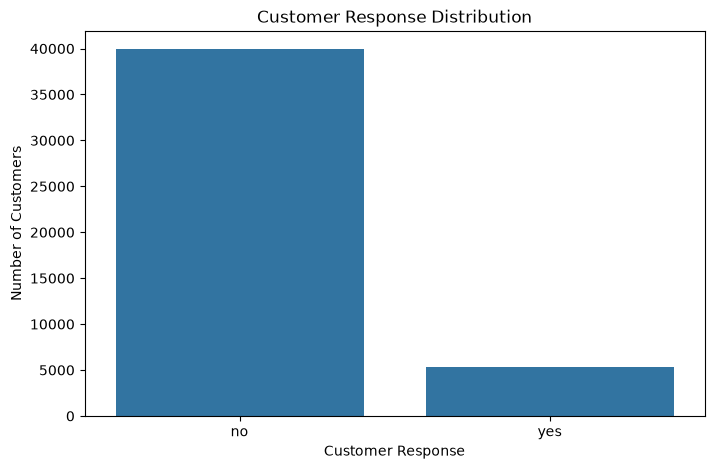

In [64]:
# Customer Response Distribution
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x='y')

plt.title('Customer Response Distribution')
plt.xlabel('Customer Response')
plt.ylabel('Number of Customers')
plt.show()

### Analysis / Observation:

- The chart shows two customer response categories: `yes` and `no`.
- A total of 39,922 customers did not subscribe to the term deposit.
- A total of 5,289 customers subscribed.
- The number of customers who did not subscribe is significantly higher than the number who subscribed.
- The overall conversion rate is approximately 11.70%.

### Conclusion:

The marketing campaign has a relatively low subscription rate, with approximately 11.70% of customer records resulting in a successful subscription. Further analysis is required to understand how customer characteristics and campaign activities are associated with subscription outcomes.

## EDA Q2: Which Job Categories Have the Highest Conversion Rates?

In [65]:
# Convert Customer Response into Numerical Values
df['converted'] = df['y'].replace({'yes': 1, 'no': 0})

In [66]:
# Calculate Conversion Rate by Job Category
job_conversion = df.groupby('job')['converted'].mean() * 100

job_conversion.sort_values(ascending=False)

job
student          28.678038
retired          22.791519
unemployed       15.502686
management       13.755551
admin.           12.202669
self-employed    11.842939
unknown          11.805556
technician       11.056996
services          8.883004
housemaid         8.790323
entrepreneur      8.271688
blue-collar       7.274969
Name: converted, dtype: object

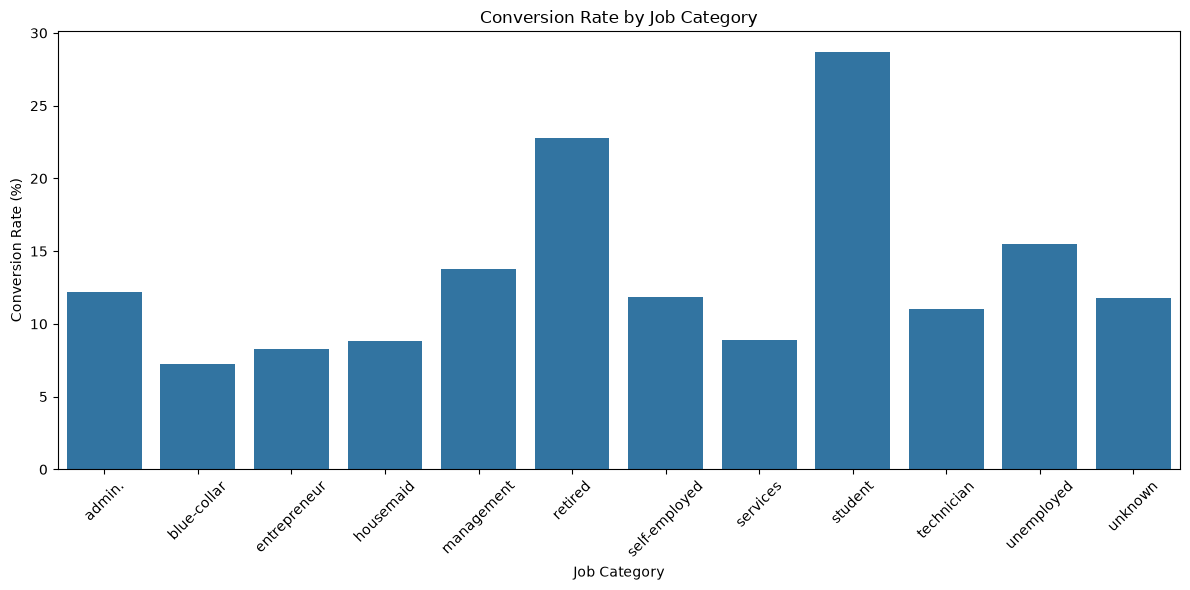

In [67]:
# Visualize Conversion Rate by Job Category
plt.figure(figsize=(12, 6))

sns.barplot(
    x=job_conversion.index,
    y=job_conversion.values
)

plt.title('Conversion Rate by Job Category')
plt.xlabel('Job Category')
plt.ylabel('Conversion Rate (%)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Analysis / Observation:

- Students have the highest conversion rate at approximately 28.68%.
- Retired customers have the second-highest conversion rate at approximately 22.79%.
- Unemployed customers have a conversion rate of approximately 15.50%.
- Management customers have a conversion rate of approximately 13.76%.
- Blue-collar customers have the lowest conversion rate at approximately 7.27%.
- The conversion rate differs across job categories.

### Conclusion:

Students and retired customers show higher subscription rates in this dataset than other job categories. The bank could investigate these customer segments further when planning future marketing campaigns. However, conversion rates alone do not establish causation or determine which segment will generate the greatest number of subscriptions.

## EDA Q3: How Does Marital Status Relate to Customer Conversion?

In [68]:
# Calculate Conversion Rate by Marital Status
marital_conversion = df.groupby('marital')['converted'].mean() * 100

marital_conversion.sort_values(ascending=False)

marital
single      14.949179
divorced    11.945458
married     10.123466
Name: converted, dtype: object

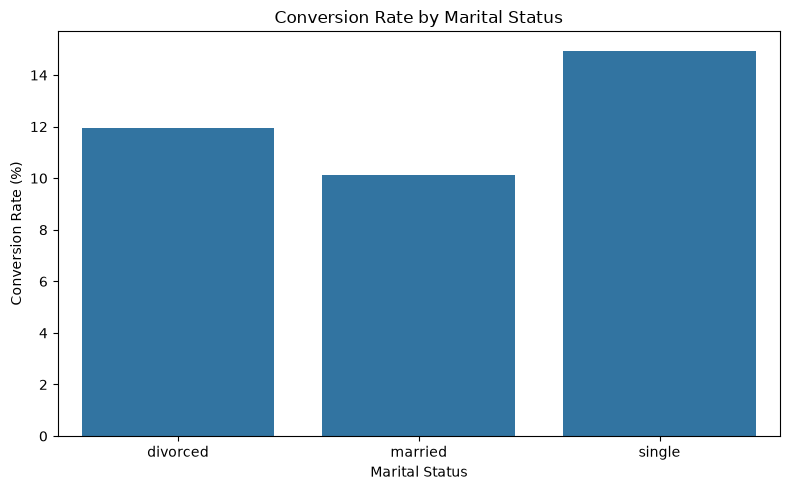

In [69]:
# Visualize Conversion Rate by Marital Status
plt.figure(figsize=(8, 5))

sns.barplot(
    x=marital_conversion.index,
    y=marital_conversion.values
)

plt.title('Conversion Rate by Marital Status')
plt.xlabel('Marital Status')
plt.ylabel('Conversion Rate (%)')
plt.tight_layout()
plt.show()

### Analysis / Observation:

- Single customers have the highest conversion rate at approximately 14.9%.
- Divorced customers have a conversion rate of approximately 12.0%.
- Married customers have the lowest conversion rate at approximately 10.1%.
- The conversion rate for single customers is approximately 4.8 percentage points higher than that of married customers.
- Conversion rates vary across marital-status categories.

### Conclusion:

Single customers show a higher subscription rate than married and divorced customers in this dataset. The bank could investigate these differences when planning customer segmentation strategies. However, marital status alone does not explain subscription behaviour, and further analysis is required to understand other contributing factors.

## EDA Q4: How Does Education Level Relate to Customer Conversion?

In [70]:
# Calculate Conversion Rate by Education Level
education_conversion = df.groupby('education')['converted'].mean() * 100

education_conversion.sort_values(ascending=False)

education
tertiary      15.00639
unknown      13.570275
secondary    10.559435
primary       8.626478
Name: converted, dtype: object

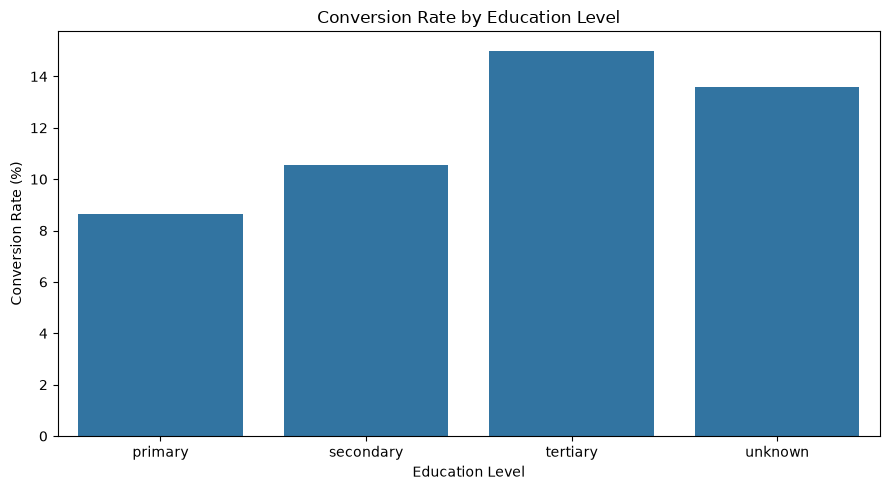

In [71]:
# Visualize Conversion Rate by Education Level
plt.figure(figsize=(9, 5))

sns.barplot(
    x=education_conversion.index,
    y=education_conversion.values
)

plt.title('Conversion Rate by Education Level')
plt.xlabel('Education Level')
plt.ylabel('Conversion Rate (%)')
plt.tight_layout()
plt.show()

## EDA Q5: How Does Age Relate to Customer Conversion?

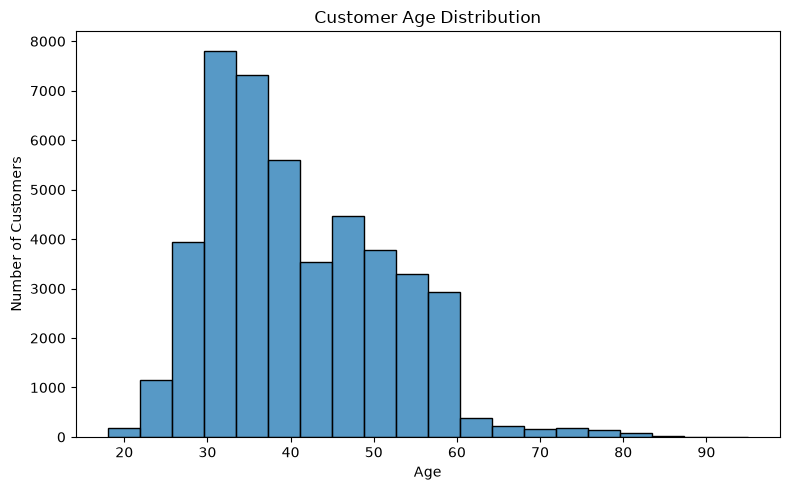

In [72]:
# Visualize Customer Age Distribution
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x='age', bins=20)

plt.title('Customer Age Distribution')
plt.xlabel('Age')
plt.ylabel('Number of Customers')
plt.tight_layout()
plt.show()

### Analysis / Observation:

- Most customer records are concentrated between approximately 27 and 40 years of age.
- The highest concentration appears around the early-to-mid 30s.
- The number of customer records generally decreases at older ages.
- Relatively few customer records belong to customers above 60 years of age.
- The age distribution is right-skewed, with a tail extending toward older ages.

### Conclusion:

The dataset contains more customer records from younger and middle-aged adults than from older customers. However, age distribution alone does not tell us which age groups are more likely to subscribe. We need to compare conversion rates across age groups to investigate subscription behaviour.

In [73]:
# Create Age Groups
df['age_group'] = pd.cut(
    df['age'],
    bins=[18, 30, 40, 50, 60, 100],
    labels=['18-30', '31-40', '41-50', '51-60', 'Above 60'],
    include_lowest=True
)

In [74]:
# Calculate Conversion Rate by Age Group
age_conversion = df.groupby('age_group', observed=False)['converted'].mean() * 100

age_conversion.sort_values(ascending=False)

age_group
Above 60    42.255892
18-30        16.28734
31-40       10.244813
51-60       10.053304
41-50        9.066643
Name: converted, dtype: object

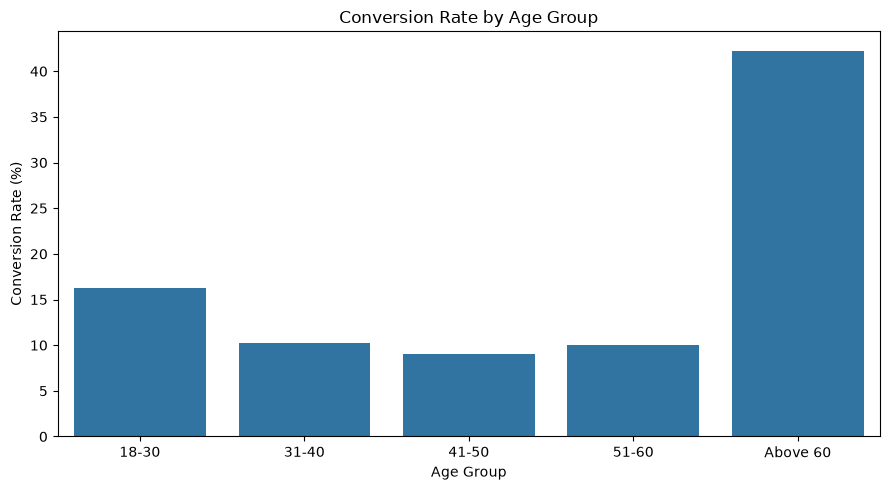

In [75]:
# Visualize Conversion Rate by Age Group
plt.figure(figsize=(9, 5))

sns.barplot(
    x=age_conversion.index,
    y=age_conversion.values
)

plt.title('Conversion Rate by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Conversion Rate (%)')
plt.tight_layout()
plt.show()

### Analysis / Observation:

- Customers above 60 years of age have the highest conversion rate at approximately 42.26%.
- Customers aged 18–30 have a conversion rate of approximately 16.29%.
- Customers aged 31–40 have a conversion rate of approximately 10.24%.
- Customers aged 51–60 have a conversion rate of approximately 10.05%.
- Customers aged 41–50 have the lowest conversion rate at approximately 9.07%.
- The conversion rate for customers above 60 is substantially higher than that of the other age groups.

### Conclusion:

Older customers show a higher subscription rate in this dataset, particularly those above 60 years of age. The bank could investigate this segment further when planning marketing campaigns. However, the number of customers in each age group should be examined before deciding how much importance to give these conversion rates.

In [76]:
# Count Customers in Each Age Group
df['age_group'].value_counts().sort_index()

age_group
18-30        7030
31-40       17687
41-50       11239
51-60        8067
Above 60     1188
Name: count, dtype: int64

## EDA Q6: How Does Contact Method Relate to Customer Conversion?

In [77]:
# Calculate Conversion Rate by Contact Method
contact_conversion = df.groupby('contact')['converted'].mean() * 100

contact_conversion.sort_values(ascending=False)

contact
cellular       14.9189
telephone    13.420509
unknown       4.070661
Name: converted, dtype: object

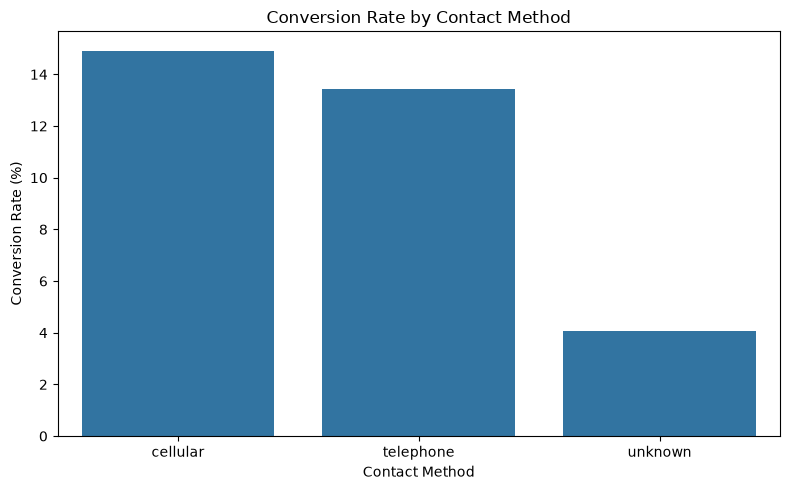

In [78]:
# Visualize Conversion Rate by Contact Method
plt.figure(figsize=(8, 5))

sns.barplot(
    x=contact_conversion.index,
    y=contact_conversion.values
)

plt.title('Conversion Rate by Contact Method')
plt.xlabel('Contact Method')
plt.ylabel('Conversion Rate (%)')
plt.tight_layout()
plt.show()

### Analysis / Observation:

- Customers contacted through cellular have the highest conversion rate at approximately 14.92%.
- Customers contacted through telephone have a conversion rate of approximately 13.42%.
- Records with an unknown contact method have the lowest conversion rate at approximately 4.07%.
- Cellular has a conversion rate approximately 1.50 percentage points higher than telephone.
- Conversion rates differ across the contact-method categories.

### Conclusion:

Customers contacted through cellular show a slightly higher subscription rate than those contacted through telephone. Records with an unknown contact method show a substantially lower conversion rate. The bank could investigate contact-channel performance and improve the recording of contact information. However, these results show an association and do not prove that the contact method itself causes higher conversion.

## EDA Q7: How Does the Number of Campaign Contacts Relate to Customer Conversion?

In [79]:
# Calculate Conversion Rate by Number of Campaign Contacts
campaign_conversion = df.groupby('campaign')['converted'].mean() * 100

campaign_conversion.sort_values(ascending=False)

campaign
1     14.597583
2     11.203519
3     11.193624
32    11.111111
4      9.000568
17     8.695652
11     7.960199
5      7.879819
6      7.126259
9      6.422018
7      6.394558
29         6.25
8      5.925926
10     5.263158
24          5.0
15     4.761905
13     4.511278
14     4.301075
21     2.857143
12     2.580645
16     2.531646
20     2.325581
43          0.0
38          0.0
39          0.0
41          0.0
58          0.0
44          0.0
46          0.0
50          0.0
51          0.0
55          0.0
36          0.0
37          0.0
25          0.0
35          0.0
34          0.0
33          0.0
31          0.0
30          0.0
28          0.0
27          0.0
26          0.0
23          0.0
22          0.0
19          0.0
18          0.0
63          0.0
Name: converted, dtype: object

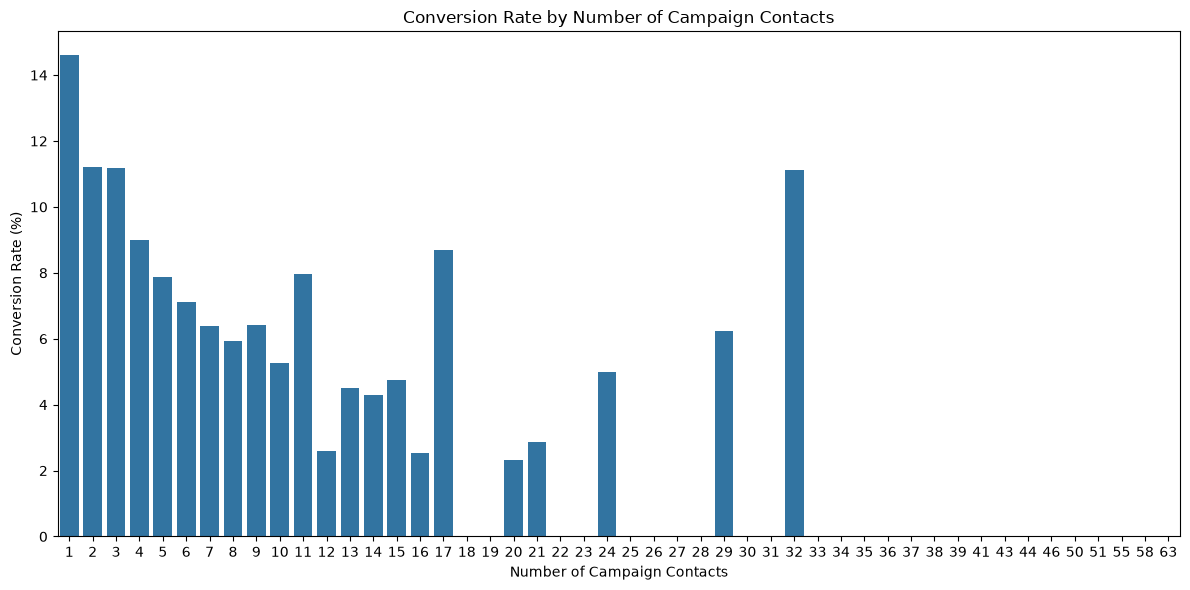

In [80]:
# Visualize Conversion Rate by Campaign Contacts
plt.figure(figsize=(12, 6))

sns.barplot(
    x=campaign_conversion.index,
    y=campaign_conversion.values
)

plt.title('Conversion Rate by Number of Campaign Contacts')
plt.xlabel('Number of Campaign Contacts')
plt.ylabel('Conversion Rate (%)')
plt.tight_layout()
plt.show()

### Analysis / Observation:

- Customers contacted once have a conversion rate of approximately 14.60%.
- Customers contacted twice have a conversion rate of approximately 11.20%.
- Customers contacted three times have a conversion rate of approximately 11.19%.
- The conversion rate generally tends to decrease as the number of campaign contacts increases, although the pattern is not consistent for every contact count.
- Some contact counts show unusually high conversion rates, which may be influenced by smaller group sizes.
- The chart contains many categories, making it difficult to identify the overall trend clearly.

### Conclusion:

The results suggest that repeated campaign contacts are not necessarily associated with higher subscription rates. The bank should investigate whether repeated contact is effective and avoid assuming that additional calls will automatically increase conversions. Group sizes should also be considered before making campaign decisions.

## EDA Q7.1: How Does Campaign Contact Frequency Relate to Conversion?

In [81]:
# Create Campaign Contact Groups
df['campaign_group'] = pd.cut(
    df['campaign'],
    bins=[0, 1, 3, 100],
    labels=['1 Contact', '2-3 Contacts', 'More than 3 Contacts']
)

In [82]:
# Calculate Conversion Rate by Campaign Contact Group
campaign_group_conversion = df.groupby(
    'campaign_group', observed=False
)['converted'].mean() * 100

campaign_group_conversion

campaign_group
1 Contact               14.597583
2-3 Contacts            11.200488
More than 3 Contacts     7.354009
Name: converted, dtype: object

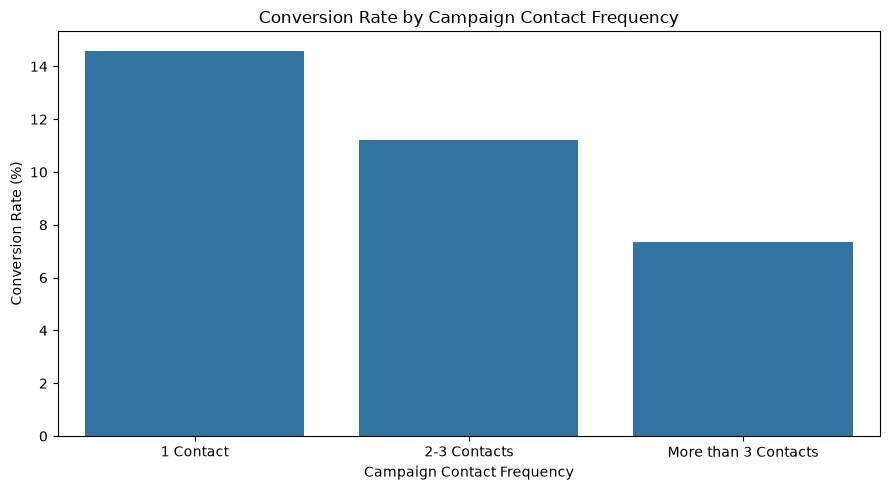

In [83]:
# Visualize Conversion Rate by Campaign Contact Group
plt.figure(figsize=(9, 5))

sns.barplot(
    x=campaign_group_conversion.index,
    y=campaign_group_conversion.values
)

plt.title('Conversion Rate by Campaign Contact Frequency')
plt.xlabel('Campaign Contact Frequency')
plt.ylabel('Conversion Rate (%)')
plt.tight_layout()
plt.show()

### Analysis / Observation:

- Customers contacted once have the highest conversion rate at approximately 14.60%.
- Customers contacted 2–3 times have a conversion rate of approximately 11.20%.
- Customers contacted more than 3 times have the lowest conversion rate at approximately 7.35%.
- The conversion rate decreases across the three campaign contact-frequency groups.
- Customers contacted once have a conversion rate approximately 7.25 percentage points higher than customers contacted more than 3 times.

### Conclusion:

The analysis shows that customers with fewer campaign contacts have higher observed conversion rates in this dataset. Repeated contact does not necessarily correspond to a higher subscription rate. The bank could investigate whether repeated calls are effective and consider avoiding excessive contact. However, these results do not prove that repeated contact causes lower conversion, because customer characteristics and previous responses may also influence the outcome.

## EDA Q8: How Does Previous Campaign Outcome Relate to Customer Conversion?

In [84]:
# Calculate Conversion Rate by Previous Campaign Outcome
poutcome_conversion = df.groupby('poutcome')['converted'].mean() * 100

poutcome_conversion.sort_values(ascending=False)

poutcome
success    64.725347
other      16.684783
failure    12.609671
unknown     9.161503
Name: converted, dtype: object

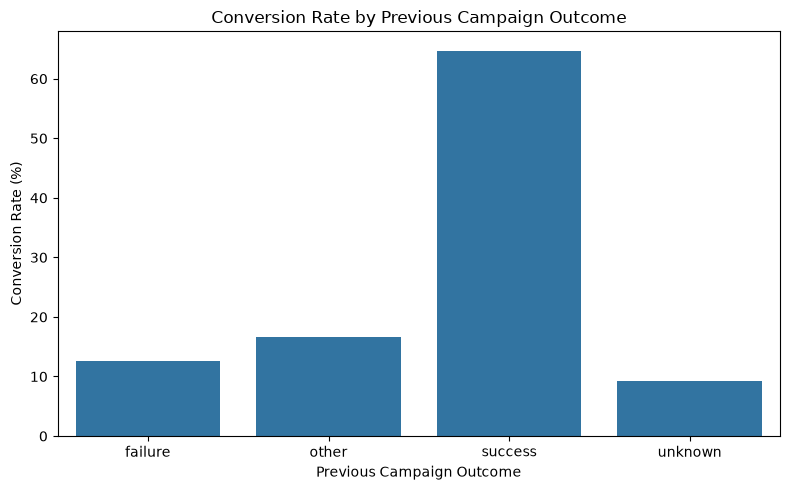

In [85]:
# Visualize Conversion Rate by Previous Campaign Outcome
plt.figure(figsize=(8, 5))

sns.barplot(
    x=poutcome_conversion.index,
    y=poutcome_conversion.values
)

plt.title('Conversion Rate by Previous Campaign Outcome')
plt.xlabel('Previous Campaign Outcome')
plt.ylabel('Conversion Rate (%)')
plt.tight_layout()
plt.show()

### Analysis / Observation:

- Customers whose previous campaign outcome was successful have the highest conversion rate at approximately 64.73%.
- Customers in the other previous-outcome category have a conversion rate of approximately 16.68%.
- Customers whose previous campaign outcome was a failure have a conversion rate of approximately 12.61%.
- Records with an unknown previous campaign outcome have the lowest conversion rate at approximately 9.16%.
- The conversion rate for customers with a previous campaign success is substantially higher than for the other categories.

### Conclusion:

Customers with a successful previous campaign outcome show a much higher subscription rate in the current campaign. Previous campaign history may therefore be a useful factor when planning customer segmentation and future marketing activities. However, the bank should also examine the number of customers in each category before deciding how much weight to give these conversion rates.

## EDA Q9: How Does Customer Account Balance Relate to Conversion?

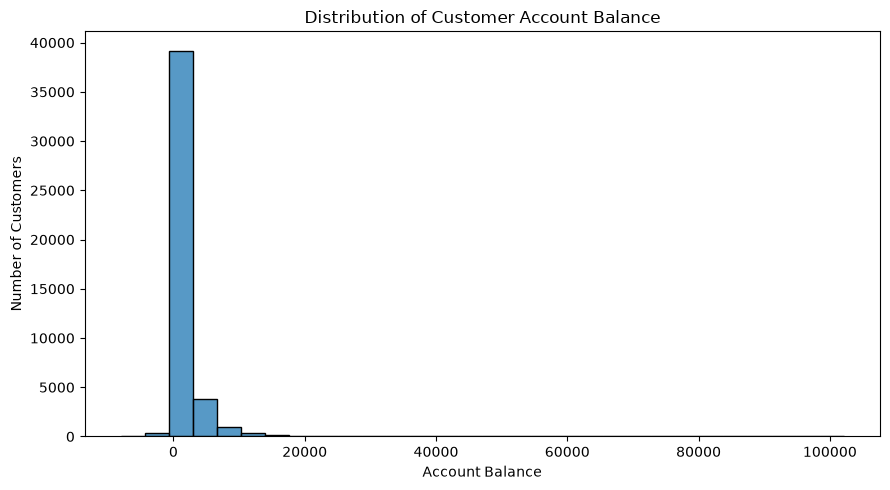

In [86]:
# Visualize Customer Account Balance Distribution
plt.figure(figsize=(9, 5))

sns.histplot(data=df, x='balance', bins=30)

plt.title('Distribution of Customer Account Balance')
plt.xlabel('Account Balance')
plt.ylabel('Number of Customers')
plt.tight_layout()
plt.show()

### Analysis / Observation:

- Most customer records have account balances concentrated toward the lower end of the distribution.
- The account balance distribution is strongly right-skewed.
- A small number of customers have very high positive balances.
- The dataset also includes customers with negative account balances.
- Extreme balance values make the distribution of typical account balances less visible in the histogram.

### Conclusion:

Customer account balances vary considerably, with most records concentrated at lower values and a small number showing very high balances. Further analysis is required to understand whether account balance is associated with customer subscription behaviour. Negative and unusually high balances should not automatically be removed because they may represent valid customer records.

## EDA Q9: How Does Account Balance Group Relate to Customer Conversion?

In [87]:
# Create Account Balance Groups
df['balance_group'] = pd.cut(
    df['balance'],
    bins=[-10000, 0, 1000, 200000],
    labels=['Negative Balance', '0-1000', 'Above 1000']
)

In [88]:
# Calculate Conversion Rate by Account Balance Group
balance_conversion = df.groupby(
    'balance_group', observed=False
)['converted'].mean() * 100

balance_conversion

balance_group
Negative Balance     6.895604
0-1000              10.896996
Above 1000          15.364637
Name: converted, dtype: object

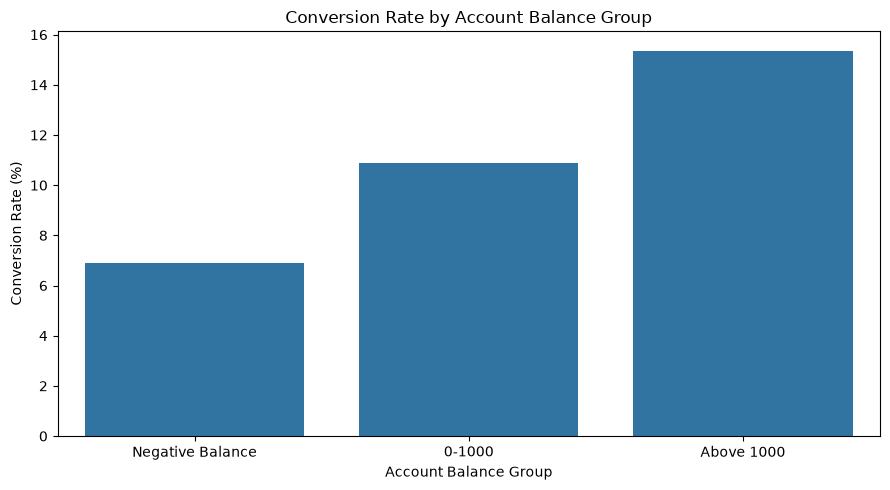

In [89]:
# Visualize Conversion Rate by Account Balance Group
plt.figure(figsize=(9, 5))

sns.barplot(
    x=balance_conversion.index,
    y=balance_conversion.values
)

plt.title('Conversion Rate by Account Balance Group')
plt.xlabel('Account Balance Group')
plt.ylabel('Conversion Rate (%)')
plt.tight_layout()
plt.show()

### Analysis / Observation:

- Customers with account balances above 1,000 have the highest conversion rate at approximately 15.36%.
- Customers with balances between 0 and 1,000 have a conversion rate of approximately 10.90%.
- Customers with negative account balances have the lowest conversion rate at approximately 6.90%.
- The conversion rate for customers with balances above 1,000 is approximately 8.46 percentage points higher than for customers with negative balances.
- Conversion rates increase across the three account balance groups.

### Conclusion:

Customers with higher account balances show higher subscription rates in this dataset. Account balance may be a useful variable for customer segmentation and further marketing analysis. However, these results show an association rather than proof that a higher account balance causes a customer to subscribe.

## EDA Q10: How Does Housing Loan Status Relate to Customer Conversion?

In [90]:
# Calculate Conversion Rate by Housing Loan Status
housing_conversion = df.groupby('housing')['converted'].mean() * 100

housing_conversion.sort_values(ascending=False)

housing
no     16.702355
yes      7.69996
Name: converted, dtype: object

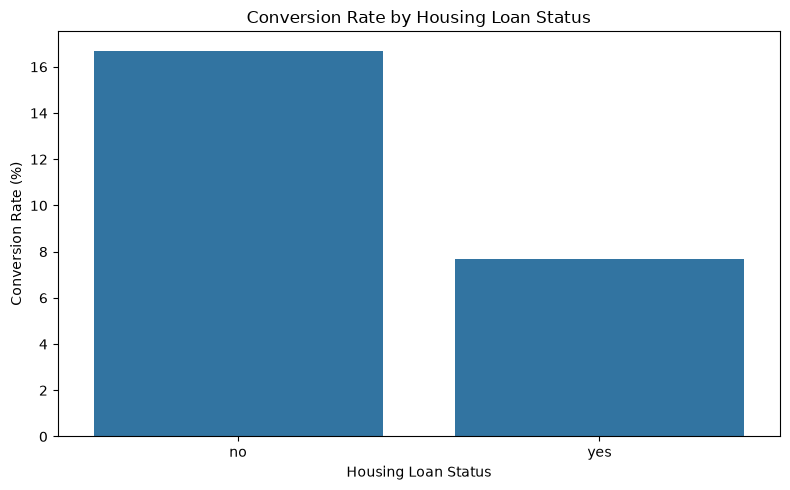

In [91]:
# Visualize Conversion Rate by Housing Loan Status
plt.figure(figsize=(8, 5))

sns.barplot(
    x=housing_conversion.index,
    y=housing_conversion.values
)

plt.title('Conversion Rate by Housing Loan Status')
plt.xlabel('Housing Loan Status')
plt.ylabel('Conversion Rate (%)')
plt.tight_layout()
plt.show()

### Analysis / Observation:

- Customers without a housing loan have the highest conversion rate at approximately 16.70%.
- Customers with a housing loan have a conversion rate of approximately 7.70%.
- The conversion rate for customers without a housing loan is approximately 9.00 percentage points higher.
- The observed conversion rate among customers without a housing loan is more than twice that of customers with a housing loan.

### Conclusion:

Customers without a housing loan show a higher subscription rate in this dataset than customers with a housing loan. Housing loan status may be useful for further customer segmentation analysis. However, this association does not establish that having a housing loan causes a customer to be less likely to subscribe.

## EDA Q11: How Does Personal Loan Status Relate to Customer Conversion?

In [92]:
# Calculate Conversion Rate by Personal Loan Status
loan_conversion = df.groupby('loan')['converted'].mean() * 100

loan_conversion.sort_values(ascending=False)

loan
no     12.655727
yes     6.681391
Name: converted, dtype: object

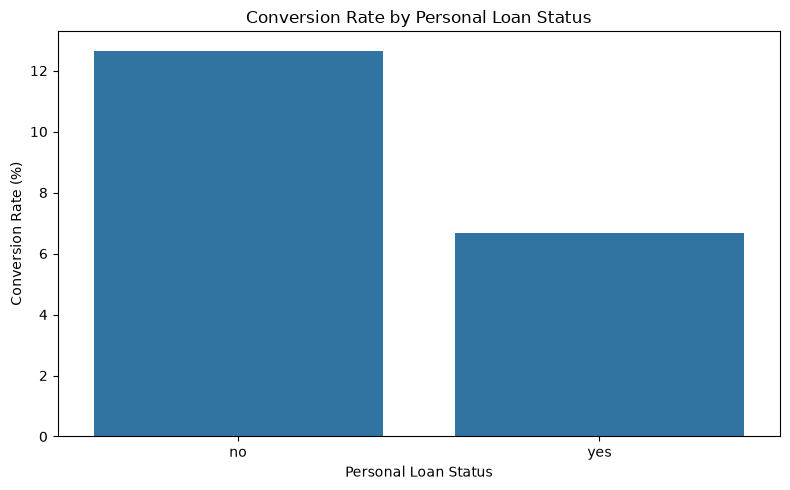

In [93]:
# Visualize Conversion Rate by Personal Loan Status
plt.figure(figsize=(8, 5))

sns.barplot(
    x=loan_conversion.index,
    y=loan_conversion.values
)

plt.title('Conversion Rate by Personal Loan Status')
plt.xlabel('Personal Loan Status')
plt.ylabel('Conversion Rate (%)')
plt.tight_layout()
plt.show()

### Analysis

- Customers **without a personal loan** have a conversion rate of approximately **12.66%**.
- Customers **with a personal loan** have a conversion rate of approximately **6.68%**.
- Customers without a personal loan show a conversion rate almost twice as high as customers with a personal loan.

### Conclusion

Customers without personal loans were more likely to subscribe to the term deposit in this dataset. However, this is an observed relationship, not proof that having a personal loan causes lower conversion.

### Q12. Conversion Rate by Month

**Business Question:** Which month has the highest customer subscription conversion rate?

In [94]:
# Calculate Conversion Rate by Month
month_conversion = df.groupby('month')['converted'].mean() * 100

month_conversion.sort_values(ascending=False)

month
mar    51.991614
dec    46.728972
sep    46.459413
oct    43.766938
apr      19.6794
feb    16.647792
aug    11.013286
jun    10.222805
nov    10.151134
jan    10.121169
jul     9.093546
may     6.719454
Name: converted, dtype: object

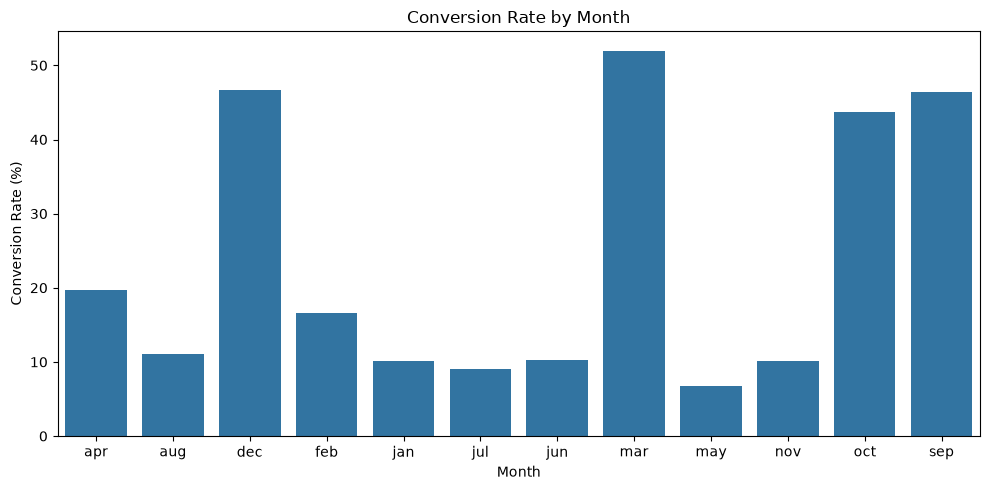

In [95]:
# Visualize Conversion Rate by Month
plt.figure(figsize=(10, 5))

sns.barplot(
    x=month_conversion.index,
    y=month_conversion.values
)

plt.title('Conversion Rate by Month')
plt.xlabel('Month')
plt.ylabel('Conversion Rate (%)')
plt.tight_layout()
plt.show()

### Analysis

- March has the highest customer subscription conversion rate at approximately **51.99%**.
- December has the second-highest conversion rate at approximately **46.73%**.
- September and October also show high conversion rates of approximately **46.46%** and **43.77%**, respectively.
- May has the lowest conversion rate at approximately **6.72%**.

### Conclusion

Customer subscription conversion rates vary significantly across months. March, December, September, and October show higher conversion rates, while May has the lowest. These findings suggest that campaign timing may influence customer responses. However, the number of customers contacted in each month should also be considered before making final marketing decisions.

# 4. Key Insights and Business Recommendations

## 4.1 Key Insights

The exploratory data analysis revealed several important patterns in customer subscription behavior. The following insights summarize the key findings related to customer demographics, campaign contact methods, previous campaign outcomes, and conversion rates.

### Key Findings

- **Overall Conversion Rate:** Approximately 11.70% of customers subscribed to the term deposit, indicating scope for improving campaign performance.
- **Job Category:** Students showed the highest conversion rate at approximately 28.68%, followed by retired customers at 22.79%.
- **Age Group:** Customers above 60 years had a conversion rate of approximately 42.26%. However, this group contained only 1,188 customers, so the result should be interpreted carefully.
- **Contact Method:** Cellular contact had a higher conversion rate (14.92%) than telephone contact (13.42%).
- **Campaign Frequency:** Customers contacted once had a conversion rate of approximately 14.60%, compared with 7.35% for customers contacted more than three times.
- **Previous Campaign Outcome:** Customers whose previous campaign was successful had a conversion rate of approximately 64.73%, making previous campaign success a strong indicator of subscription likelihood.
- **Account Balance:** Customers with balances above 1,000 had a conversion rate of approximately 15.36%, compared with 6.90% among customers with negative balances.
- **Loan Status:** Customers without a personal loan had a conversion rate of 12.66%, compared with 6.68% among customers with a personal loan.
- **Monthly Performance:** March had the highest observed conversion rate (51.99%), while May had the lowest (6.72%). Monthly customer counts should be considered before drawing firm conclusions.


## 4.2 Business Recommendations

Based on the findings, we suggest practical strategies to improve customer targeting, campaign timing, and subscription conversion rates.

### Business Recommendations

Based on the exploratory data analysis, the following recommendations may help improve marketing campaign performance:

1. **Prioritize Previously Successful Customers:** Customers with a successful previous campaign outcome showed a conversion rate of approximately 64.73%. The marketing team can consider prioritizing similar customers for future campaigns.

2. **Improve Customer Targeting:** Students and retired customers showed higher conversion rates than several other job categories. The bank can test targeted marketing strategies for these segments while considering the number of customers in each group.

3. **Optimize Contact Methods:** Cellular contact showed a higher conversion rate than telephone contact. The bank can evaluate cellular outreach further to determine whether it improves campaign effectiveness.

4. **Avoid Excessive Follow-ups:** Customers contacted once showed a higher conversion rate than those contacted more than three times. The bank should review its follow-up strategy to reduce unnecessary repeated contacts.

5. **Optimize Campaign Timing:** March, December, September, and October showed relatively high conversion rates. The bank can investigate these months further by comparing customer counts and campaign costs before adjusting its schedule.

6. **Focus on Relevant Customer Segments:** Customers without personal loans and customers with account balances above 1,000 showed higher conversion rates in this dataset. These patterns can guide further testing of customer segments rather than being used as strict selection rules.

7. **Measure Campaign Performance Regularly:** Track conversion rates, the number of customers contacted, and total subscriptions to evaluate whether future campaign changes deliver measurable improvements.

# 5. Limitations and Assumptions

## 5.1 Limitations

- **Imbalanced Customer Responses:** The dataset contains 39,922 customers who did not subscribe and only 5,289 who subscribed. This imbalance should be considered when interpreting the results.
- **Unknown Values:** Some categorical columns, such as job, education, contact, and previous campaign outcome, contain unknown values that may affect the analysis.
- **Observed Relationships:** The analysis identifies patterns and associations but does not establish that a customer characteristic directly causes subscription.
- **Limited Business Context:** The dataset does not provide campaign costs or revenue details, so profitability and return on investment cannot be calculated.
- **Historical Data:** The results describe the available dataset and may not represent customer behavior in future campaigns.

## 5.2 Assumptions

- Each row represents one customer contact record in the dataset.
- The target column `y` indicates whether the customer subscribed to the term deposit (`yes` or `no`).
- Conversion rates are calculated as the percentage of records with a `yes` response within each group.
- Unknown category values are retained rather than automatically removed.
- The findings are used to identify potential marketing opportunities, not to guarantee future conversion rates.